In [79]:
import torch
import numpy as np
import torch.functional as F
import matplotlib.pyplot as plt
%matplotlib inline

In [80]:
with open('../data/names.txt', 'r') as f:
    names = f.read().splitlines()
print(f'Number of names: {len(names)}')

Number of names: 32033


In [81]:
# create vocab
vocab = ['.'] + sorted(list(set(''.join(names))))
stoi = { ch: index for index, ch in enumerate(vocab) }
itos = { index: ch for ch, index in stoi.items() }

In [82]:
# create training set
def build_dataset(words, block_size=3):
    X, Y = [], []
    for word in words:
        context = [0] * block_size
        for w in word + '.':
            ix = stoi[w]
            Y.append(ix)
            X.append(context)
            context = context[1:] + [ix]
    XS = torch.tensor(X)
    YS = torch.tensor(Y)
    return XS, YS

import random

random.shuffle(names)

pdev, pval, ptest = 0.8, 0.1, 0.1
data_size = len(names)
block_size = 3

sdev = int(data_size * pdev)
sval = int(data_size * (pdev + pval))
Xtr, ytr = build_dataset(names[:sdev], block_size)
Xval, yval = build_dataset(names[sdev: sval], block_size)
Xtest, ytest = build_dataset(names[sval:], block_size)

In [83]:
# contants
vocab_size = len(vocab)
embed_dim = 10
batch_size = 32
hidden_nuerons = 200

rng = torch.Generator().manual_seed(2147483647)

C = torch.randn(size=(vocab_size, embed_dim), generator=rng)
W1 = torch.randn(size=(embed_dim*block_size, hidden_nuerons), generator=rng) * 5 / 3 * (embed_dim*block_size)**-0.5
b1 = torch.randn(size=(hidden_nuerons, ), generator=rng) * 0.1
W2 = torch.randn(size=(hidden_nuerons, vocab_size), generator=rng) * 0.01
b2 = torch.randn(size=(vocab_size, ), generator=rng) * 0.1

# for batch normalization scale and shift
bnscale = torch.ones(size=(1, hidden_nuerons))
bnshift = torch.zeros(size=(1, hidden_nuerons))
bnmean_running = torch.ones(size=(1, hidden_nuerons))
bnstd_running = torch.ones(size=(1, hidden_nuerons))

parameters = [C, W1, b1, W2, b2, bnscale, bnshift]

for p in parameters:
    p.requires_grad = True


In [84]:
epochs = 200000
# epochs = 1
learning_rate = 0.1
batch_size = 32
lossi = []

for epoch in range(epochs):
    batch = torch.randint(0, len(Xtr), size=(batch_size, ), generator=rng)
    Xb, yb = Xtr[batch], ytr[batch]

    #fwad pass
    emb = C[Xb]
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1 + b1

    # batch normalization
    bnmeani = hpreact.mean(0, keepdim=True)
    bnstdi = hpreact.std(0, keepdim=True)
    with torch.no_grad():
        bnmean_running = 0.999 * bnmean_running + 0.001 * bnmeani
        bnstd_running = 0.999 * bnstd_running + 0.001 * bnstdi
        
    hpreact = bnscale * (hpreact - bnmeani) / bnstdi + bnshift

    h = torch.tanh(hpreact)
    
    logits = h @ W2 + b2
    counts = logits.exp()
    ypred = counts / counts.sum(1, keepdim=True)

    # #loss
    loss = -ypred[torch.arange(batch_size), yb].log().mean()

    # # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update parameters
    lr = learning_rate if epoch < epochs / 2 else learning_rate / 10
    for p in parameters:
        p.data = p.data - lr * p.grad

    if epoch % 10000 == 0:
        print(f'epoch: {epoch} | {epochs} : {loss.item(): .4f}')
    lossi.append(loss.log10().item())

epoch: 0 | 200000 :  3.3215
epoch: 10000 | 200000 :  2.4873
epoch: 20000 | 200000 :  2.2208
epoch: 30000 | 200000 :  2.5772
epoch: 40000 | 200000 :  2.3259
epoch: 50000 | 200000 :  1.9886
epoch: 60000 | 200000 :  2.1327
epoch: 70000 | 200000 :  2.3185
epoch: 80000 | 200000 :  2.4239
epoch: 90000 | 200000 :  2.0078
epoch: 100000 | 200000 :  2.3748
epoch: 110000 | 200000 :  1.8419
epoch: 120000 | 200000 :  1.9776
epoch: 130000 | 200000 :  2.0615
epoch: 140000 | 200000 :  1.7867
epoch: 150000 | 200000 :  2.4340
epoch: 160000 | 200000 :  2.0554
epoch: 170000 | 200000 :  1.8891
epoch: 180000 | 200000 :  2.2210
epoch: 190000 | 200000 :  2.2211


In [75]:
hpreact.shape
m = hpreact.mean(0, keepdim=True)
std = hpreact.std(0, keepdim=True)

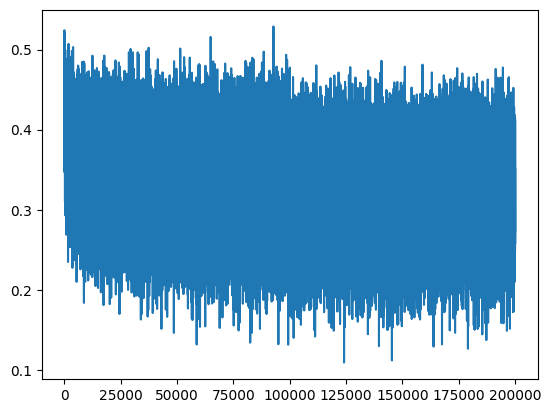

In [76]:
plt.plot(lossi)

In [ ]:
@torch.no_grad()
def split_loss(split):
    dataset = {'train': (Xtr, ytr),
             'val': (Xval, yval),
             'test': (Xtest, ytest)
        }
    x, y = dataset[split]
    emb = C[x]
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1 + b1
    hpreact = bnscale * (hpreact - bnmean_running) / bnstd_running  + bnshift
    h = torch.tanh(hpreact) 
    logits = h @ W2 + b2
    counts = logits.exp()
    ypred = counts / counts.sum(1, keepdim=True)
    loss = -ypred[torch.arange(len(x)), y].log().mean()
    return loss.item()

print(split_loss('train'))
print(split_loss('val'))

2.063941717147827
2.127643346786499


In [1]:
import torch

class Linear:
    def __init__(self, fanin, fanout, g, bias = True):
        self.weights = torch.randn(size=(fanin, fanout), generator=g) / (fanin) ** 0.5
        self.bias = torch.zeros(size=(fanout, )) if bias else None


    def __call__(self, X):
        out = X @ self.weights
        if self.bias:
            out = out + self.bias
        return out

    def parameters(self):
        return [self.weights] + [] if not self.bias else [self.bias]